# 08 – Học từ phản hồi của kế toán: đánh giá bằng mô phỏng theo thời gian

**Câu hỏi:** nếu hệ thống học từ đánh giá "đúng / cảnh báo giả" của kế toán để hạ mức các tín hiệu hay sai, số hồ sơ cảnh báo
giả giảm được bao nhiêu, và phải đánh đổi bao nhiêu vấn đề thật bị hạ xuống mức ghi chú?

**Vì sao phải mô phỏng.** Dữ liệu Oklahoma PCard không có kết luận thật của kế toán. Notebook này dùng một *kế toán mô phỏng*
(`src/feedback_sim.py`). Mọi con số dưới đây phụ thuộc vào giả định của mô phỏng, nên được báo cáo như một **thí nghiệm có điều
kiện**, không phải hiệu quả đo trên người dùng thật.

**Cơ chế được đánh giá** (`src/feedback.py`, cũng là code chạy trong ứng dụng):
- Chỉ hiệu chỉnh các tín hiệu dựa trên dấu hiệu gián tiếp: R01 (mô tả chung chung), R03 (trùng hóa đơn), R07 (cửa hàng chưa duyệt),
  giao dịch bất thường và cụm mua dồn của mô hình. R02, R04, R05, R06, R08 là quy định cứng của quy chế nên **được bảo vệ**.
- Phản hồi được gom theo *ngữ cảnh* (1 hoặc 2 thuộc tính: nhóm chi phí, khoảng tiền, số đơn vị đã dùng nhà cung cấp, số lần mua lặp lại
  của người chi / của đơn vị, số lần trả đúng số tiền đó). Tỷ lệ đúng p của ngữ cảnh có hậu nghiệm Beta(1 + đúng, 1 + giả).
- Kế toán có thể đánh giá nhầm với tỷ lệ ε, nên tỷ lệ "đúng" quan sát được là q = p(1 − 2ε) + ε ∈ [ε, 1 − ε]; hậu nghiệm được cắt về
  đoạn này.
- Nếu chắc chắn ≥ 95% rằng p < τ thì **đề xuất** hạ tín hiệu xuống mức Thấp (vẫn ghi chú). Trong mô phỏng coi như quản lý duyệt
  ngay, áp dụng từ tháng sau. Đề xuất đang áp dụng chỉ bị gỡ khi độ chắc chắn giảm dưới 50%.
- **τ là tham số nghiệp vụ**, không phải siêu tham số để tối ưu: hạ mức khi p < τ nghĩa là chấp nhận để 1 vấn đề thật xuống mức ghi
  chú để bớt (1 − τ)/τ lần review thừa. Mặc định τ = 0,15 (≈ 1 đổi 6). Notebook báo cáo cả đường đánh đổi theo τ thay vì một con số.

**Đơn vị tính là hồ sơ**, như trong ứng dụng: cả ngày mua dồn của một người chi là một hồ sơ; mỗi tín hiệu của hồ sơ nhận một đánh giá.
Mỗi tháng kế toán xem 400 hồ sơ ở cả hai bên so sánh; khi có hiệu chỉnh, 10% trong số đó dành cho kiểm tra mẫu hồ sơ đã bị hạ mức
(để phát hiện đề xuất sai).

In [1]:
import sys, time
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from IPython.display import Markdown, display

from src.data_loader import load_pcard
from src.labels import add_expense_group
from src.anomaly import inject_anomalies, apply_injection
from src.case import CaseEngine
from src.feedback import signal_table, levels, CALIBRATABLE, MODEL_SIGNALS
from src.feedback_sim import oracle_facts, truth_probability, latent_truth, simulate, injected_cases, SCENARIOS

pd.set_option('display.width', 180); pd.set_option('display.max_colwidth', 140)
BLUE, ORANGE, INK, INK2, GRID = '#2a78d6', '#eb6834', '#1c2a3a', '#4c5b68', '#d5ddd9'
plt.rcParams.update({'font.family': ['Arial', 'DejaVu Sans'], 'font.size': 10, 'axes.edgecolor': INK2,
                     'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2, 'axes.grid': True,
                     'grid.color': GRID, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Dữ liệu cho mô phỏng

Dùng cùng cách tạo dữ liệu đánh giá như notebook 04: chèn các giao dịch bất thường giả lập (tăng đột biến, cửa hàng lạ, mua dồn,
ghi sổ trễ) từ tháng 1/2026, rồi chạy toàn bộ rule và mô hình. Mô phỏng chạy 8 tháng, 1/2026 – 8/2026 (R07 bắt đầu áp dụng từ 1/2026).

In [2]:
t0 = time.time()
df = add_expense_group(load_pcard())
data = apply_injection(df, inject_anomalies(df, pd.Period('2026-01', 'M')))
eng = CaseEngine(data)
start = pd.Period('2026-01', 'M')
sig = signal_table(eng.df, eng.hits)
sig = sig[sig['month'] >= start].reset_index(drop=True)
facts = oracle_facts(eng.df)
injected = injected_cases(eng.df)
injected = injected[injected >= start]
print(f'{time.time() - t0:.0f} giây; {len(sig):,} tín hiệu trong {sig.case_id.nunique():,} hồ sơ; '
      f'{len(injected):,} hồ sơ chứa giao dịch giả lập')
sig.pivot_table(index='month', columns='signal', values='case_id', aggfunc='nunique').fillna(0).astype(int)

49 giây; 57,172 tín hiệu trong 25,073 hồ sơ; 1,249 hồ sơ chứa giao dịch giả lập


signal,R01,R02,R03,R04,R05,R06,R07,R08,cum_mua_don,mo_hinh
month,,,,,,,,,,
2026-01,1170,199,340,152,240,12,807,42,188,350
2026-02,1219,214,426,170,287,11,918,36,205,339
2026-03,1398,270,434,159,345,16,1182,48,220,394
2026-04,1353,270,378,202,348,14,1139,71,199,433
2026-05,1309,291,362,159,283,12,1099,39,189,360
2026-06,1457,348,346,193,301,15,1224,26,179,415
2026-07,1389,298,342,121,339,15,1171,35,136,316
2026-08,1375,310,360,160,343,16,1084,29,153,329


## 2. Kế toán mô phỏng

Mỗi tín hiệu có một **sự thật ẩn** (đúng / giả), rút ngẫu nhiên một lần với xác suất dưới đây. Một hồ sơ là *vấn đề thật* nếu ít nhất
một tín hiệu của nó đúng, hoặc nó chứa giao dịch giả lập. Kế toán đánh giá nhầm 10% (ε = 0,1).

| Tín hiệu | Lý do của kế toán (kịch bản "khớp") | P(đúng) | Hệ thống có thấy lý do này không |
|---|---|---|---|
| R01 mô tả chung chung | nhà cung cấp quen của đơn vị (≥ 10 lần mua trong 180 ngày) / còn lại | 0,15 / 0,6 | gần đúng: số lần đơn vị mua trong 90 ngày |
| R03 trùng hóa đơn | lệ phí, hội phí, đào tạo (đăng ký nhiều người) / phí định kỳ (cùng số tiền ở tháng trước) / còn lại | 0,1 / 0,05 / 0,7 | có (nhóm chi phí) / gần đúng (số lần trả đúng số tiền trong 90 ngày) |
| R07 cửa hàng chưa duyệt | nhà cung cấp phổ biến (≥ 10 **người chi** đã dùng) / còn lại | 0,1 / 0,5 | gần đúng: số **đơn vị** đã dùng |
| Mô hình (giao dịch, cụm) | vé máy bay, khách sạn / còn lại | 0,05 / 0,3 | có (nhóm chi phí) |
| R02, R04, R05, R06, R08 | quy định cứng | 0,95 | (không hiệu chỉnh) |
| Hồ sơ chứa giao dịch giả lập | vấn đề thật | 1 | |

Ba kịch bản:
- **"khop" (thuận lợi):** như bảng. Một phần lý do chính là ngữ cảnh hệ thống thấy được, nên đây gần với mức tốt nhất có thể.
- **"mot_phan":** lý do theo nhóm chi phí (lệ phí đăng ký, vé máy bay/khách sạn) chỉ đúng với 60% người chi (yếu tố ẩn: chuyến công tác
  / đăng ký đã được duyệt trước). Trong cùng nhóm chi phí, tỷ lệ đúng bị pha trộn.
- **"an" (bất lợi):** lý do nằm ở yếu tố hệ thống không thấy (R07 phụ thuộc người chi có được tin cậy hay không; các tín hiệu khác có
  P(đúng) cố định 0,4 hoặc 0,3). Không có gì để học, và cơ chế **không được gây hại**.

In [3]:
TRUTH = {sc: latent_truth(sig, facts, sc) for sc in SCENARIOS}
pd.DataFrame({sc: pd.Series(t).groupby(sig['signal'].values).mean() for sc, t in TRUTH.items()}).round(2).T

,R01,R02,R03,R04,R05,R06,R07,R08,cum_mua_don,mo_hinh
khop,0.43,0.95,0.30,0.95,0.95,0.95,0.49,0.94,0.19,0.38
mot_phan,0.43,0.95,0.38,0.95,0.95,0.95,0.49,0.94,0.25,0.40
an,0.41,0.95,0.40,0.95,0.95,0.95,0.39,0.94,0.31,0.42


## 3. Kết quả theo tháng (kịch bản "khop", τ = 0,15, 5 lần chạy)

- **Tỷ lệ cảnh báo giả** = số hồ sơ được cảnh báo (Cần review trở lên) không phải vấn đề thật / số hồ sơ được cảnh báo.
- **Tỷ lệ phát hiện** = số hồ sơ có vấn đề thật được cảnh báo / số hồ sơ có vấn đề thật (gồm cả hồ sơ giả lập hệ thống gốc bỏ sót).
- **Bị hạ mức** = hồ sơ có vấn đề thật mà hệ thống gốc cảnh báo nhưng sau hiệu chỉnh chỉ còn ghi chú.

In [4]:
SEEDS = range(5)
late = lambda r: r[r['month'] >= '2026-05']

def run(sc='khop', **kw):
    return pd.concat([simulate(sig, TRUTH[sc], injected, seed=seed, **kw)[0].assign(seed=seed) for seed in SEEDS])

base, cal = run(calibrate=False), run()
cols = ['alerts', 'false_alerts', 'false_alert_rate', 'detection', 'injected_detection', 'missed']
pd.concat({'Không học': base.groupby('month')[cols].mean(), 'Có học từ phản hồi': cal.groupby('month')[cols].mean()}, axis=1).round(3)

Không học                                                                   Có học từ phản hồi                                                                  
           alerts false_alerts false_alert_rate detection injected_detection missed             alerts false_alerts false_alert_rate detection injected_detection missed
month                                                                                                                                                                   
2026-01    2611.0       1021.0            0.391     0.965              0.695    0.0             2611.0       1021.0            0.391     0.965              0.695    0.0
2026-02    2908.0       1158.0            0.398     0.961              0.530    0.0             2908.0       1158.0            0.398     0.961              0.530    0.0
2026-03    3426.0       1386.0            0.405     0.957              0.483    0.0             3378.0       1343.4            0.398     0.954              0.483    5.4
2026-04    3376.0       1296.0            0.384     0.965              0.561    0.0             3264.4       1196.0            0.365     0.959              0.558   11.6
2026-05    3110.0       1254.0            0.403     0.962              0.507    0.0             2996.8       1157.6            0.385     0.953              0.499   16.8
2026-06    3338.0       1350.0            0.404     0.959              0.401    0.0             3233.8       1259.2            0.389     0.953              0.400   13.4
2026-07    3159.0       1312.0            0.415     0.962              0.421    0.0             3028.2       1199.2            0.395     0.953              0.417   18.0
2026-08    3189.0       1320.0            0.414     0.956              0.420    0.0             3077.0       1221.4            0.396     0.949              0.419   13.4

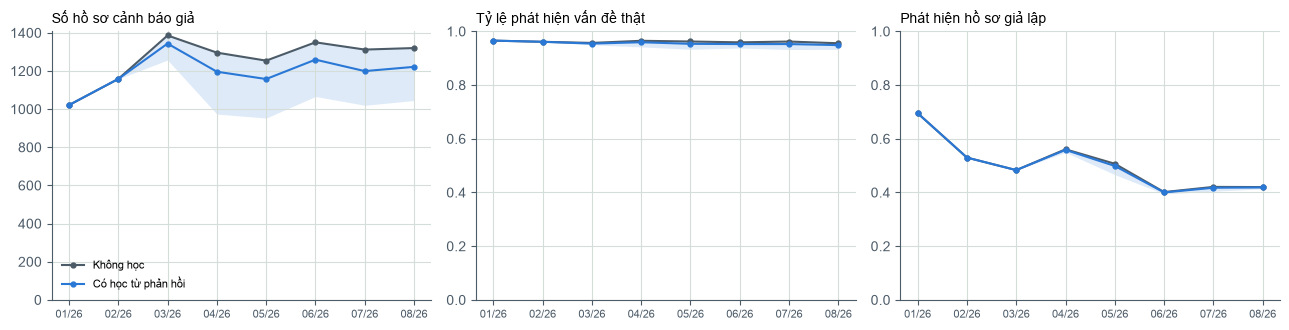

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col, title in zip(axes, ['false_alerts', 'detection', 'injected_detection'],
                          ['Số hồ sơ cảnh báo giả', 'Tỷ lệ phát hiện vấn đề thật', 'Phát hiện hồ sơ giả lập']):
    for frame, label, color in [(base, 'Không học', INK2), (cal, 'Có học từ phản hồi', BLUE)]:
        g = frame.groupby('month')[col]
        x = np.arange(g.ngroups)
        ax.plot(x, g.mean(), marker='o', ms=3.5, color=color, label=label)
        ax.fill_between(x, g.min(), g.max(), color=color, alpha=0.15, lw=0)
    ax.set_xticks(x, [mm[5:] + '/26' for mm in g.mean().index], fontsize=8)
    ax.set_title(title, fontsize=10, loc='left')
    if col != 'false_alerts':
        ax.set_ylim(0, 1)
axes[0].set_ylim(bottom=0); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 4. So sánh ba kịch bản và mức trần

**Mức trần:** nếu hệ thống biết đúng lý do của kế toán và hạ mức chính xác các tín hiệu có P(đúng) < τ, nó giảm được bao nhiêu hồ sơ
cảnh báo giả? So với mức trần để biết cơ chế học đạt bao nhiêu phần so với lý tưởng. Số liệu là trung bình 4 tháng cuối (5/2026 – 8/2026),
khi đã có phản hồi.

In [6]:
def summary(frame):
    g = late(frame).groupby('seed')
    return {'Hồ sơ cảnh báo / tháng': g['alerts'].mean().mean(), 'Cảnh báo giả / tháng': g['false_alerts'].mean().mean(),
            'Tỷ lệ cảnh báo giả': g['false_alert_rate'].mean().mean(), 'Tỷ lệ phát hiện': g['detection'].mean().mean(),
            'Phát hiện hồ sơ giả lập': g['injected_detection'].mean().mean(), 'Bị hạ mức / tháng': g['missed'].mean().mean()}

def ceiling(tau, sc):
    m = (sig['month'] >= pd.Period('2026-05', 'M')).to_numpy()
    s = sig[m].assign(truth=TRUTH[sc][m], p=truth_probability(sig, facts, sc)[m])
    cases = pd.Index(s['case_id'].unique()).union(injected.index[injected >= pd.Period('2026-05', 'M')])
    t = s.groupby('case_id')['truth'].any().reindex(cases, fill_value=False)
    t[t.index.isin(injected.index)] = True
    b = levels(s, None, cases, by='case_id') != 'Bình thường'
    a = levels(s, (s['p'] < tau) & s['signal'].isin(CALIBRATABLE + MODEL_SIGNALS), cases, by='case_id') != 'Bình thường'
    return 1 - (a & ~t).sum() / (b & ~t).sum(), (b & ~a & t).sum() / 4

BASE = {'khop': summary(base)}
rows = []
for sc in SCENARIOS:
    b = BASE.setdefault(sc, summary(run(sc, calibrate=False)))
    c = summary(cal) if sc == 'khop' else summary(run(sc))
    ceil = ceiling(0.15, sc)
    rows.append({'Kịch bản': sc, 'Cảnh báo giả / tháng (gốc)': b['Cảnh báo giả / tháng'],
                 'Giảm cảnh báo giả': 1 - c['Cảnh báo giả / tháng'] / b['Cảnh báo giả / tháng'],
                 'Tỷ lệ cảnh báo giả': f"{b['Tỷ lệ cảnh báo giả']:.3f} → {c['Tỷ lệ cảnh báo giả']:.3f}",
                 'Tỷ lệ phát hiện': f"{b['Tỷ lệ phát hiện']:.3f} → {c['Tỷ lệ phát hiện']:.3f}",
                 'Phát hiện hồ sơ giả lập': f"{b['Phát hiện hồ sơ giả lập']:.3f} → {c['Phát hiện hồ sơ giả lập']:.3f}",
                 'Bị hạ mức / tháng': c['Bị hạ mức / tháng'],
                 'Mức trần: giảm cảnh báo giả': ceil[0], 'Mức trần: bị hạ mức / tháng': ceil[1]})
pd.DataFrame(rows).set_index('Kịch bản').round(3)

,Cảnh báo giả / tháng (gốc),Giảm cảnh báo giả,Tỷ lệ cảnh báo giả,Tỷ lệ phát hiện,Phát hiện hồ sơ giả lập,Bị hạ mức / tháng,Mức trần: giảm cảnh báo giả,Mức trần: bị hạ mức / tháng
Kịch bản,,,,,,,,
khop,1309.00,0.076,0.409 → 0.391,0.960 → 0.952,0.437 → 0.434,15.40,0.181,35.25
mot_phan,1283.50,0.014,0.401 → 0.398,0.960 → 0.958,0.437 → 0.436,3.35,0.155,25.50
an,1357.75,0.000,0.424 → 0.424,0.959 → 0.959,0.437 → 0.437,0.00,0.213,17.50


### Các đề xuất hệ thống đưa ra (kịch bản "khop", cuối tháng 8/2026, số lần xuất hiện trong 5 lần chạy)

Đây là những gì quản lý sẽ thấy trên trang *Hiệu chỉnh cảnh báo*. Đối chiếu với lý do ẩn ở mục 2.

In [7]:
seen, text = Counter(), {}
for seed in SEEDS:
    _, h = simulate(sig, TRUTH['khop'], injected, seed=seed)
    for p in h[-1]['proposals']:
        seen[p['key']] += 1; text[p['key']] = p['text']
pd.DataFrame([{'Đề xuất': text[k], 'Số lần chạy có đề xuất này': n} for k, n in seen.most_common()])

,Đề xuất,Số lần chạy có đề xuất này
0,"R03 (Trùng hóa đơn) khi nhóm chi phí “Lệ phí, hội phí, đào tạo & sự kiện”: 50/313 cảnh báo được kế toán xác nhận đúng. Đề xuất hạ xuống ...",2
1,"R03 (Trùng hóa đơn) khi nhóm chi phí “Lệ phí, hội phí, đào tạo & sự kiện”, số tiền < $500: 36/207 cảnh báo được kế toán xác nhận đúng. Đ...",2
2,"R03 (Trùng hóa đơn) khi nhóm chi phí “Lệ phí, hội phí, đào tạo & sự kiện”, số lần đơn vị mua ở đây trong 90 ngày trước 1–19: 50/266 cảnh...",2
3,"R03 (Trùng hóa đơn) khi nhóm chi phí “Lệ phí, hội phí, đào tạo & sự kiện”, số lần người chi trả đúng số tiền này ở đây trong 90 ngày trư...",2
4,R01 (Thiếu chứng từ / mô tả) khi số lần đơn vị mua ở đây trong 90 ngày trước ≥ 20: 55/289 cảnh báo được kế toán xác nhận đúng. Đề xuất h...,1
5,"R01 (Thiếu chứng từ / mô tả) khi nhóm chi phí “Chưa xác định (cửa hàng bán đủ loại)”, số lần người chi mua ở đây trong 90 ngày trước ≥ 5...",1
6,"R03 (Trùng hóa đơn) khi nhóm chi phí “Lệ phí, hội phí, đào tạo & sự kiện”, số đơn vị đã dùng nhà cung cấp 1–4: 37/182 cảnh báo được kế t...",1
7,"R03 (Trùng hóa đơn) khi nhóm chi phí “Lệ phí, hội phí, đào tạo & sự kiện”, số lần người chi mua ở đây trong 90 ngày trước ≥ 5: 8/72 cảnh...",1


## 5. Đánh đổi theo τ và các yếu tố khác

Đường đánh đổi theo τ (kịch bản "khop"); mỗi điểm là trung bình 4 tháng cuối, 5 lần chạy.

In [8]:
def grid_row(label, sc='khop', **kw):
    b, c = BASE[sc], summary(run(sc, **kw))
    return {'Thiết lập': label, 'Giảm cảnh báo giả': 1 - c['Cảnh báo giả / tháng'] / b['Cảnh báo giả / tháng'],
            'Cảnh báo giả bớt / tháng': b['Cảnh báo giả / tháng'] - c['Cảnh báo giả / tháng'],
            'Bị hạ mức / tháng': c['Bị hạ mức / tháng'],
            'Thay đổi tỷ lệ phát hiện': c['Tỷ lệ phát hiện'] - b['Tỷ lệ phát hiện'],
            'Phát hiện hồ sơ giả lập': c['Phát hiện hồ sơ giả lập']}

taus = [0.1, 0.15, 0.2, 0.25, 0.3]
curve = pd.DataFrame([grid_row(f'τ = {t}', tau=t) for t in taus])
curve['Mức trần: giảm cảnh báo giả'] = [ceiling(t, 'khop')[0] for t in taus]
curve['Mức trần: bị hạ mức / tháng'] = [ceiling(t, 'khop')[1] for t in taus]
curve.round(3)

,Thiết lập,Giảm cảnh báo giả,Cảnh báo giả bớt / tháng,Bị hạ mức / tháng,Thay đổi tỷ lệ phát hiện,Phát hiện hồ sơ giả lập,Mức trần: giảm cảnh báo giả,Mức trần: bị hạ mức / tháng
0,τ = 0.1,0.007,9.25,1.00,-0.001,0.437,0.072,16.25
1,τ = 0.15,0.076,99.65,15.40,-0.008,0.434,0.181,35.25
2,τ = 0.2,0.140,183.30,33.45,-0.017,0.432,0.439,95.50
3,τ = 0.25,0.240,314.15,71.45,-0.036,0.420,0.439,95.50
4,τ = 0.3,0.325,425.95,100.25,-0.051,0.405,0.439,95.50


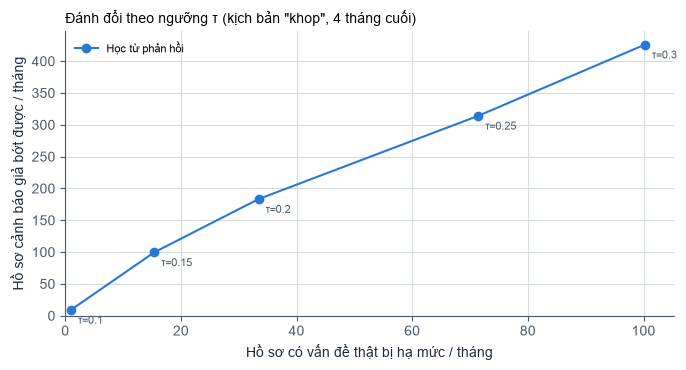

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(curve['Bị hạ mức / tháng'], curve['Cảnh báo giả bớt / tháng'], marker='o', color=BLUE, label='Học từ phản hồi')
for t, x, y in zip(taus, curve['Bị hạ mức / tháng'], curve['Cảnh báo giả bớt / tháng']):
    ax.annotate(f'τ={t}', (x, y), textcoords='offset points', xytext=(5, -10), fontsize=8, color=INK2)
ax.set_xlabel('Hồ sơ có vấn đề thật bị hạ mức / tháng'); ax.set_ylabel('Hồ sơ cảnh báo giả bớt được / tháng')
ax.set_title('Đánh đổi theo ngưỡng τ (kịch bản "khop", 4 tháng cuối)', fontsize=10, loc='left')
ax.set_xlim(left=0); ax.set_ylim(bottom=0)
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

Các yếu tố khác (τ = 0,15): mức nhầm lẫn của kế toán, ước lượng sai mức nhầm lẫn, số hồ sơ được xem mỗi tháng, có kiểm tra mẫu hay không,
và kịch bản bất lợi với τ lớn.

In [10]:
other = pd.DataFrame([
    grid_row('Mặc định (ε = 0,1, 400 hồ sơ, kiểm tra mẫu 10%)'),
    grid_row('Kế toán không nhầm (ε = 0)', noise=0.0),
    grid_row('Kế toán nhầm 20%, hệ thống biết đúng', noise=0.2),
    grid_row('Nhầm 10%, hệ thống giả định 0 (thận trọng)', noise=0.1, assumed_noise=0.0),
    grid_row('Nhầm 10%, hệ thống giả định 20% (quá tay)', noise=0.1, assumed_noise=0.2),
    grid_row('Xem 200 hồ sơ / tháng', budget=200),
    grid_row('Xem 800 hồ sơ / tháng', budget=800),
    grid_row('Không kiểm tra mẫu hồ sơ đã hạ mức', explore=0.0),
    grid_row('Kịch bản "an", τ = 0,3', sc='an', tau=0.3),
])
other.round(3)

,Thiết lập,Giảm cảnh báo giả,Cảnh báo giả bớt / tháng,Bị hạ mức / tháng,Thay đổi tỷ lệ phát hiện,Phát hiện hồ sơ giả lập
0,"Mặc định (ε = 0,1, 400 hồ sơ, kiểm tra mẫu 10%)",0.076,99.65,15.40,-0.008,0.434
1,Kế toán không nhầm (ε = 0),0.087,113.85,16.25,-0.008,0.435
2,"Kế toán nhầm 20%, hệ thống biết đúng",0.024,31.80,4.45,-0.002,0.437
3,"Nhầm 10%, hệ thống giả định 0 (thận trọng)",0.027,34.90,4.85,-0.002,0.437
4,"Nhầm 10%, hệ thống giả định 20% (quá tay)",0.176,230.30,45.95,-0.023,0.430
5,Xem 200 hồ sơ / tháng,0.007,9.70,1.05,-0.001,0.437
6,Xem 800 hồ sơ / tháng,0.075,97.95,15.55,-0.008,0.434
7,Không kiểm tra mẫu hồ sơ đã hạ mức,0.040,52.60,6.70,-0.003,0.437
8,"Kịch bản ""an"", τ = 0,3",0.010,13.00,8.50,-0.004,0.437


## 6. Nhận xét

Các con số cụ thể nằm ở các bảng phía trên; phần này tóm tắt điều rút ra được.

1. **Cơ chế thực hiện đúng đánh đổi mà τ quy định.** Ở mọi mức τ, số cảnh báo giả bớt được trên mỗi vấn đề thật bị hạ mức xấp xỉ
   (1 − τ)/τ trở lên. τ = 0,15 cho mức giảm nhỏ nhưng rất ít vấn đề bị hạ; τ càng lớn càng bớt nhiều cảnh báo giả nhưng càng nhiều
   vấn đề xuống mức ghi chú (vẫn được ghi trong hồ sơ). Chọn τ là quyết định của quản lý, không phải của mô hình.
2. **Mức giảm còn xa mức trần.** Phần lớn hồ sơ cảnh báo giả chỉ có một tín hiệu R01 hoặc R07. Lý do kế toán bác các tín hiệu này
   (nhà cung cấp quen của đơn vị, nhà cung cấp nhiều người chi đã dùng) chỉ quan sát được gần đúng, và các ngữ cảnh có P(đúng) sát τ
   thì không bao giờ "chắc chắn dưới τ" được. Phần lớn đề xuất là R03 ở nhóm lệ phí/đào tạo (đúng một lý do ẩn của
   kế toán), nhưng mỗi dạng ngữ cảnh chỉ xuất hiện ở 1–2 trong 5 lần chạy: với 400 hồ sơ/tháng, bằng chứng tích lũy chậm.
3. **Không gây hại khi không có gì để học.** Ở kịch bản "an", với τ mặc định gần như không có đề xuất; ngay cả τ = 0,3 cũng chỉ vài
   hồ sơ bị hạ mức mỗi tháng. Kịch bản "mot_phan" nằm giữa hai kịch bản kia.
4. **Bất thường hiếm được giữ.** Tỷ lệ phát hiện hồ sơ giả lập gần như không đổi ở τ mặc định, nhờ tách "giao dịch bất thường" và
   "cụm mua dồn" thành hai tín hiệu (bản đầu gộp làm một đã làm mất phần lớn bất thường giả lập).
5. **Nhầm lẫn của kế toán phải được ước lượng.** Giả định ε quá cao thì hệ thống hạ mức quá tay; giả định 0 thì gần như không học được.
   Khi triển khai cần ước lượng ε bằng cách cho người thứ hai review lại một mẫu nhỏ.

**Bài học về cách đo.** Bản đầu của mô phỏng tính theo *giao dịch*: một ngày mua dồn vé máy bay có hàng chục giao dịch nên được đếm hàng
chục lần, cho con số giảm cảnh báo giả 35%. Tính theo *hồ sơ* như ứng dụng thật thì con số đó không còn. Notebook này dùng cách tính
theo hồ sơ.

**Hạn chế.** Kết quả phụ thuộc hoàn toàn vào giả định của kế toán mô phỏng (xác suất, lý do, mức nhầm lẫn), không thay cho đánh giá với
kế toán thật. Mô phỏng coi mọi đề xuất được duyệt ngay; trên ứng dụng, quản lý có thể từ chối. Ứng dụng chưa có bước kiểm tra mẫu hồ sơ
đã hạ mức như trong mô phỏng. "Vấn đề thật" chỉ tính trong hồ sơ hệ thống gốc đã cảnh báo cộng hồ sơ giả lập; vấn đề mà rule và mô hình
không bắt được từ đầu thì không đo được. Các tháng dùng chung một tập dữ liệu; 5 lần chạy chỉ phản ánh độ biến động do chọn mẫu hồ sơ và
do nhầm lẫn của kế toán.